# Binance global, 30+ coins: data and universe (Steps 1–2)

Goal: rebuild the strategy on a larger, **point-in-time** universe of Binance global coins, as suggested in the feedback (removes the full-sample coin selection of the 13-coin version and tests whether the 2026 momentum weakness is a 13-coin problem).

Rules decided before looking at any results:
- **2020–2024: development**, 2025: validation, 2026: reported only (it is no longer a clean out-of-sample period, because the 13-coin results for 2026 have been seen).
- **No survivorship bias**: candidates come from *all* Binance USDT spot pairs, including coins that later collapsed or were delisted (LUNA, FTT, ...).
- **No look-ahead in the universe**: at each month start, keep the 30 coins with the highest average daily dollar volume over the *previous* 90 days.

Data: Binance's public archive `data.binance.vision` (monthly zip files up to Sep-2026, daily files for Oct-2026). All downloads are cached in `data/`, so re-running the notebook does not download again.

In [1]:
import io, os, re, zipfile
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option('display.width', 200)

START, END_MONTH = '2020-01', '2026-09'                  # monthly files
OCT_DAYS = pd.date_range('2026-10-01', '2026-10-31')      # daily files for the last month
N_UNIV = 30          # coins in the universe
N_CAND = 40          # candidates for the 1h download (a buffer above N_UNIV)
VOL_WIN = 90         # days of past volume used to rank coins
MIN_DAYS = 60        # a coin needs data on at least 60 of those 90 days
PEG_RANGE = 0.04     # pegged asset: max/min of daily closes over those 90 days below 1.04

BASE = 'https://data.binance.vision/data/spot'
COLUMNS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
           'num_trades', 'taker_base_volume', 'taker_quote_volume', 'ignore']

session = requests.Session()
session.mount('https://', requests.adapters.HTTPAdapter(pool_maxsize=32))

def get_zip(url):
    # one kline zip file -> DataFrame (close, quote_volume), or None if the file does not exist
    r = session.get(url, timeout=60)
    if r.status_code != 200:                 # coin not listed (yet) / delisted that month
        return None
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        d = pd.read_csv(z.open(z.namelist()[0]), header=None, names=COLUMNS)
    d = d[pd.to_numeric(d['open_time'], errors='coerce').notna()]
    t = d['open_time'].astype('int64')
    t = t.where(t < 1e14, t // 1000)          # Binance switched to microseconds in 2025 (some files mix both units)
    d.index = pd.to_datetime(t, unit='ms')
    return d[['close', 'quote_volume']].astype(float)

def download(symbols, freq, months=None, days=None):
    # all monthly (and optionally daily) files for each symbol -> panel with columns (field, symbol)
    months = months if months is not None else pd.period_range(START, END_MONTH, freq='M').strftime('%Y-%m')
    urls = [(s, f'{BASE}/monthly/klines/{s}/{freq}/{s}-{freq}-{m}.zip') for s in symbols for m in months]
    if days is not None:
        urls += [(s, f'{BASE}/daily/klines/{s}/{freq}/{s}-{freq}-{d:%Y-%m-%d}.zip') for s in symbols for d in days]
    with ThreadPoolExecutor(32) as ex:
        res = list(ex.map(lambda u: get_zip(u[1]), urls))
    out = {}
    for s in symbols:
        parts = [r for (sym, _), r in zip(urls, res) if sym == s and r is not None]
        if parts:
            d = pd.concat(parts).sort_index()
            out[s] = d[~d.index.duplicated()]
    return pd.concat(out, axis=1).swaplevel(axis=1).sort_index(axis=1)

def cached(path, fn):
    if os.path.exists(path):
        return pd.read_pickle(path)
    x = fn()
    x.to_pickle(path)
    return x

## Step 1. Data

### 1.1 All USDT spot pairs

List every symbol in the archive and keep the USDT pairs, excluding leveraged tokens (`...UP`, `...DOWN`, `...BULL`, `...BEAR`), stablecoins, fiat currencies and wrapped/pegged tokens (not real crypto risk).

Why: a stablecoin is cash and a gold token follows gold, so momentum, beta and reversal mean nothing for them; stablecoins also have huge volume and would take universe slots; and in the strategies they distort the market return, the volatility-adjusted momentum ranks (volatility ≈ 0) and BAB (beta ≈ 0, always in the low-beta leg).

The list is completed in Step 2 by a data rule (pegged assets are detected from their prices), because a hand-written list misses new or dead stablecoins. *Fix after the first test run: UST, USD1 and the gold token XAUT were missing from the list and entered the universe (UST in Mar–May 2022, USD1 and XAUT in 2026).*

In [2]:
def list_symbols():
    syms, marker = [], ''
    while True:
        r = session.get('https://s3-ap-northeast-1.amazonaws.com/data.binance.vision',
                        params={'prefix': 'data/spot/monthly/klines/', 'delimiter': '/', 'marker': marker}, timeout=60).text
        syms += re.findall(r'<Prefix>data/spot/monthly/klines/([^/<]+)/</Prefix>', r)
        m = re.search(r'<NextMarker>(.*?)</NextMarker>', r)
        if not m:
            return syms
        marker = m.group(1)

EXCLUDE = {'USDC', 'BUSD', 'TUSD', 'FDUSD', 'USDP', 'PAX', 'DAI', 'USDS', 'USDE', 'RLUSD', 'XUSD', 'U', 'AEUR',
           'EUR', 'GBP', 'AUD', 'WBTC', 'BETH', 'PAXG',
           'UST', 'USD1', 'XAUT'}   # added after the first test run
all_syms = list_symbols()
usdt = [s for s in all_syms if s.endswith('USDT')
        and not re.search(r'(UP|DOWN|BULL|BEAR)USDT$', s) and s[:-4] not in EXCLUDE]
print(f'{len(all_syms)} symbols in the archive, {len(usdt)} USDT crypto pairs kept')

3767 symbols in the archive, 702 USDT crypto pairs kept


### 1.2 Daily volume of every pair → candidates

Daily klines for all pairs (~55,000 small files, ~10 minutes the first time). They are only used to find which coins were ever liquid enough: at each month start, rank the coins on their average daily dollar volume over the past 90 days; **candidates = every coin that was ever in the top 40**. This includes coins that later died, because the ranking is done at each date with the data available then.

**Pegged-asset rule:** at each month start, a coin whose daily closes over the past 90 days stay within a 4% range (max / min < 1.04) is treated as a pegged asset and cannot be selected. It catches USD- and EUR-pegged stablecoins (and an algorithmic stablecoin while it holds its peg) without a list; no real crypto coin moves less than 4% in 90 days. Gold tokens move more than that, so they stay in the list.

In [3]:
daily_all = cached('data/global_all_1d.pk', lambda: download(usdt, '1d'))
dvol_d = daily_all['quote_volume'][[s for s in usdt if s in daily_all['quote_volume'].columns]]   # the list may have grown since the download
close_d = daily_all['close'][dvol_d.columns]
print('daily panel:', dvol_d.shape, dvol_d.index.min().date(), '->', dvol_d.index.max().date())

pegged_log = {}

def top_by_volume(dvol, n, close, win=VOL_WIN, min_days=MIN_DAYS):
    # at each month start t: coins ranked on average daily $ volume over [t-win, t), using past data only.
    # A coin needs >= min_days days of data in the window and must have traded on the last day before t,
    # and must not be a pegged asset (daily closes within a PEG_RANGE range over the window).
    out = {}
    for t in pd.date_range(dvol.index.min() + pd.Timedelta(f'{win}D'), dvol.index.max(), freq='MS'):
        past = dvol.loc[t - pd.Timedelta(f'{win}D'): t - pd.Timedelta('1s')]
        pc = close.loc[t - pd.Timedelta(f'{win}D'): t - pd.Timedelta('1s'), past.columns]
        pegged = (pc.max()/pc.min() - 1 < PEG_RANGE)
        ok = (past.notna().sum() >= min_days) & past.iloc[-1].gt(0)
        pegged_log[t] = sorted(pegged[ok & pegged].index)
        avg = past.mean()[ok & ~pegged]
        out[t] = avg.rank(ascending=False) <= n
    return pd.DataFrame(out).T.fillna(False)

cand_mask = top_by_volume(dvol_d, N_CAND, close_d)
pegged_any = sorted({c for v in pegged_log.values() for c in v})
print(f'{len(pegged_any)} pairs detected as pegged at some month start (and liquid enough to be considered):', ', '.join(pegged_any))
candidates = sorted(cand_mask.columns[cand_mask.any()])
print(f'{len(candidates)} candidates (ever in the top {N_CAND})')

daily panel: (2465, 677) 2020-01-01 -> 2026-09-30


4 pairs detected as pegged at some month start (and liquid enough to be considered): BFUSDUSDT, EURIUSDT, KGSTUSDT, SUSDUSDT
281 candidates (ever in the top 40)


### 1.3 Hourly klines for the candidates

Same source and format as the 13-coin data: 1h close and dollar (USDT) volume, Jan-2020 → Oct-2026.

**Re-used tickers.** A ticker can be given to a different coin: after the May-2022 collapse, `LUNAUSDT` was suspended and later re-used for the new LUNA 2.0. If a ticker has no data for more than 7 days, the part after the gap is treated as a **new coin** (`<ticker>_2`), so returns and signals never mix the two.

In [4]:
def split_reused(panel, max_gap='7D'):
    # split a ticker into two coins at any gap without data longer than max_gap
    close, qv = panel['close'].copy(), panel['quote_volume'].copy()
    splits = {}
    for s in list(close.columns):
        idx = close[s].dropna().index
        gaps = idx.to_series().diff()
        big = gaps[gaps > pd.Timedelta(max_gap)]
        for k, (t, g) in enumerate(big.items(), start=2):
            new = f'{s}_{k}'
            close[new], qv[new] = close[s].where(close.index >= t), qv[s].where(qv.index >= t)
            close.loc[close.index >= t, s] = np.nan
            qv.loc[qv.index >= t, s] = np.nan
            splits[new] = (t - g, t)
    return close.sort_index(axis=1), qv.sort_index(axis=1), splits

raw_1h = cached('data/global_cand_1h.pk', lambda: download(candidates, '1h', days=OCT_DAYS))
missing = sorted(set(candidates) - set(raw_1h.columns.get_level_values(1)))
if missing:                                         # new candidates (e.g. after the exclusion list changed)
    print('downloading 1h data for new candidates:', ', '.join(missing))
    raw_1h = pd.concat([raw_1h, download(missing, '1h', days=OCT_DAYS)], axis=1).sort_index(axis=1)
    raw_1h.to_pickle('data/global_cand_1h.pk')
raw_1h = raw_1h.loc[:, raw_1h.columns.get_level_values(1).isin(candidates)]   # drop pairs that are no longer candidates
raw_1h = raw_1h.reindex(pd.date_range(raw_1h.index.min(), raw_1h.index.max(), freq='h'))   # regular hourly grid
px_1h, qv_1h, splits = split_reused(raw_1h)
px_1h = px_1h.where(px_1h > 0)        # a zero price is a data error

print('hourly panel:', px_1h.shape, px_1h.index.min(), '->', px_1h.index.max())
print('tickers split into two coins:')
for new, (a, b) in splits.items():
    print(f'  {new}: no data {a:%Y-%m-%d} -> {b:%Y-%m-%d}')

downloading 1h data for new candidates: HOMEUSDT, KATUSDT, SYNUSDT


/tmp/ipykernel_1694960/1252483107.py:52: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  return pd.concat(out, axis=1).swaplevel(axis=1).sort_index(axis=1)


hourly panel: (59904, 284) 2020-01-01 00:00:00 -> 2026-10-31 23:00:00
tickers split into two coins:
  CVCUSDT_2: no data 2022-12-09 -> 2023-05-12
  FTTUSDT_2: no data 2022-11-15 -> 2023-09-22
  LUNAUSDT_2: no data 2022-05-13 -> 2022-05-31


**Checks.** First and last date of each coin (coins that stop before Oct-2026 were delisted or renamed), missing data after listing, and the largest absolute 1h return (to spot bad prints).

In [5]:
r1h = px_1h.pct_change(fill_method=None)
info = pd.DataFrame({
    'first date': px_1h.apply(lambda s: s.first_valid_index()),
    'last date':  px_1h.apply(lambda s: s.last_valid_index()),
    'missing % after first': px_1h.apply(lambda s: s[s.first_valid_index():s.last_valid_index()].isna().mean()*100).round(2),
    'median $vol/hour': qv_1h.median().round(0),
    'max |1h return|': r1h.abs().max().round(2),
}).sort_values('median $vol/hour', ascending=False)
end = px_1h.index.max() - pd.Timedelta('2D')
print(f'{(info["last date"] < end).sum()} of {len(info)} coins stop before the end of the sample (delisted / renamed)')
display(info[info['last date'] < end].sort_values('last date'))
display(info.sort_values('max |1h return|', ascending=False).head(10))

56 of 284 coins stop before the end of the sample (delisted / renamed)


,first date,last date,missing % after first,median $vol/hour,max |1h return|
ERDUSDT,2020-01-01 00:00:00,2020-08-31 02:00:00,0.21,46591.0,0.21
LENDUSDT,2020-05-15 08:00:00,2020-10-12 02:00:00,0.08,230543.0,0.13
BTTUSDT,2020-01-01 00:00:00,2022-01-17 03:00:00,0.17,325480.0,0.50
GXSUSDT,2020-05-13 14:00:00,2022-04-25 03:00:00,0.12,39618.0,0.75
LUNAUSDT,2020-08-21 10:00:00,2022-05-13 00:00:00,0.12,4471141.0,2.83
FTTUSDT,2020-01-01 00:00:00,2022-11-15 04:00:00,0.12,240777.0,0.39
SRMUSDT,2020-08-11 13:00:00,2022-11-28 02:00:00,0.09,342708.0,0.53
BTCSTUSDT,2021-01-13 06:00:00,2022-11-28 02:00:00,0.66,139575.0,0.44
CVCUSDT,2020-01-01 00:00:00,2022-12-09 02:00:00,0.12,61084.0,0.34
ANCUSDT,2022-01-25 11:00:00,2022-12-27 02:00:00,0.00,258039.0,1.52


,first date,last date,missing % after first,median $vol/hour,max |1h return|
UNFIUSDT,2020-11-19 06:00:00,2024-11-06 02:00:00,0.05,227920.0,2.92
LUNAUSDT,2020-08-21 10:00:00,2022-05-13 00:00:00,0.12,4471141.0,2.83
ANCUSDT,2022-01-25 11:00:00,2022-12-27 02:00:00,0.00,258039.0,1.52
SANTOSUSDT,2021-12-01 11:00:00,2026-10-31 23:00:00,0.00,49122.0,1.28
LUNAUSDT_2,2022-05-31 06:00:00,2026-10-31 23:00:00,0.00,147034.0,1.20
OGUSDT,2020-12-30 06:00:00,2026-10-31 23:00:00,0.03,53713.0,1.04
CYBERUSDT,2023-08-15 12:00:00,2026-10-31 23:00:00,0.00,83746.0,1.04
SANDUSDT,2020-08-14 13:00:00,2026-10-31 23:00:00,0.03,338947.0,1.00
FFUSDT,2025-09-29 13:00:00,2026-10-31 23:00:00,0.00,70660.0,0.99
TRUUSDT,2021-01-19 07:00:00,2026-04-28 02:00:00,0.03,66905.0,0.93


## Step 2. Point-in-time universe (rolling volume filter)

At the start of each month, from the hourly data: average daily dollar volume over the previous 90 days → **top 30**, excluding pegged assets (same 4% rule as in 1.2). The universe is held for the month. Strategies may only hold coins that are in the universe at that time.

A coin that is delisted during the month simply stops having returns; this is a limitation (in reality the last trade happens at a bad price), but it only matters for a few coins.

In [6]:
dvol_1h = qv_1h.resample('1D').sum(min_count=1)           # daily $ volume from the hourly data
pegged_log = {}
univ_m = top_by_volume(dvol_1h, N_UNIV, px_1h.resample('1D').last())   # month start x coin, True = in the universe

px4 = px_1h.resample('4h').last()
ret = px4.pct_change(fill_method=None)                       # 4h returns, all candidates
univ = univ_m.reindex(ret.index, method='ffill').fillna(False).astype(bool)[ret.columns]
univ = univ & ret.notna()                                    # in the universe and traded during the bar

ret.to_pickle('data/global30_ret_4h.pk')
univ.to_pickle('data/global30_univ_4h.pk')
px_1h.to_pickle('data/global30_px_1h.pk')
qv_1h.to_pickle('data/global30_vol_1h.pk')
print('saved: data/global30_ret_4h.pk, data/global30_univ_4h.pk, data/global30_px_1h.pk, data/global30_vol_1h.pk')
print('universe from', univ_m.index[0].date(), 'to', univ_m.index[-1].date(), f'({len(univ_m)} months)')
excluded = pd.Series({t: ', '.join(v) for t, v in pegged_log.items() if v})
print('pegged assets excluded at month starts (among the candidates):')
print(excluded.groupby(excluded).apply(lambda s: f"{s.index.min():%Y-%m} -> {s.index.max():%Y-%m} ({len(s)} months)").to_string())

saved: data/global30_ret_4h.pk, data/global30_univ_4h.pk, data/global30_px_1h.pk, data/global30_vol_1h.pk
universe from 2020-04-01 to 2026-10-01 (79 months)
pegged assets excluded at month starts (among the candidates):
Series([], )


**Checks.** Number of coins per month, how many coins ever enter the universe, how often it changes, and the overlap with the 13 coins of the original project.

coins per month: min 30, max 30
216 different coins are in the universe at some point
average number of coins replaced per month: 4.2
original 13 coins: 74% of the time in the universe


,ETHUSDT,BNBUSDT,BTCUSDT,XRPUSDT,ADAUSDT,LINKUSDT,TRXUSDT,DOGEUSDT,LTCUSDT,SOLUSDT,...,MMTUSDT,CHRUSDT,PIXELUSDT,ZKUSDT,OPNUSDT,BSWUSDT,BREVUSDT,KSMUSDT,ERAUSDT,LAYERUSDT
months in the universe,79,79,79,79,78,74,70,69,68,65,...,1,1,1,1,1,1,1,1,1,1


,coins in the universe during the year
2020,"ADA, ALGO, ATOM, BAND, BAT, BCH, BNB, BTC, BTT..."
2021,"1INCH, AAVE, ADA, ALGO, ALICE, ATOM, AVAX, AXS..."
2022,"ADA, ALGO, ALICE, ANC, APE, ATOM, AVAX, AXS, B..."
2023,"ADA, AGIX, ALGO, APE, APT, ARB, ARK, ARPA, ATO..."
2024,"1000SATS, AAVE, ADA, ALT, APT, ARB, AVAX, BB, ..."
2025,"2Z, AAVE, ACT, ADA, AIXBT, APT, ARB, AVAX, AVN..."
2026,"AAVE, ADA, ALLO, ARB, ASTER, AT, AVAX, BANK, B..."


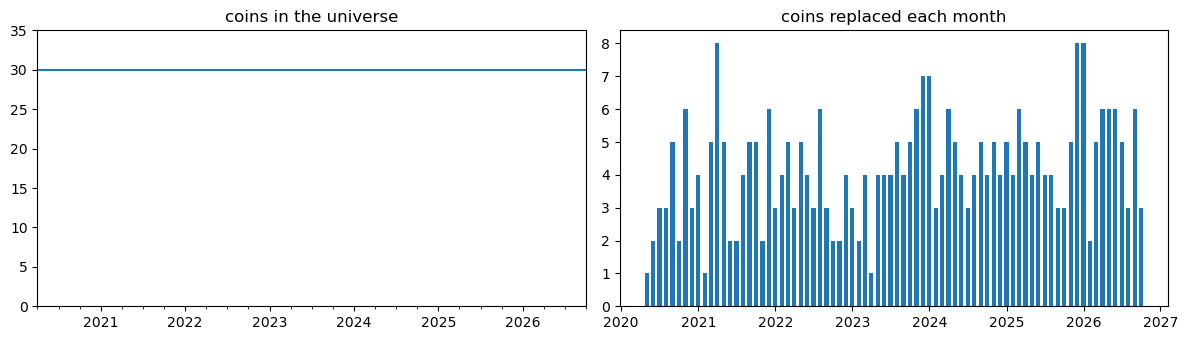

In [7]:
n_coins = univ_m.sum(axis=1)
changes = (univ_m.astype(int).diff().abs().sum(axis=1)/2).iloc[1:]
months_in = univ_m.sum().sort_values(ascending=False)
months_in = months_in[months_in > 0]

orig13 = pd.read_pickle('data/px_liquid_1h.pk').columns
print(f'coins per month: min {n_coins.min()}, max {n_coins.max()}')
print(f'{len(months_in)} different coins are in the universe at some point')
print(f'average number of coins replaced per month: {changes.mean():.1f}')
print(f'original 13 coins: {univ_m[orig13.intersection(univ_m.columns)].mean().mean()*100:.0f}% of the time in the universe')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
n_coins.plot(ax=ax[0], title='coins in the universe', ylim=(0, N_UNIV + 5))
ax[1].bar(changes.index, changes.values, width=20)
ax[1].set_title('coins replaced each month')
plt.tight_layout()

display(months_in.rename('months in the universe').to_frame().T)
yearly = univ_m.groupby(univ_m.index.year).apply(lambda x: ', '.join(sorted(c.replace('USDT', '') for c in x.columns[x.any()])))
yearly.rename('coins in the universe during the year').to_frame()

**Conclusion.**
- **Data:** 686 USDT pairs → 281 candidates (ever in the daily top 40) → hourly panel of 284 coins (three re-used tickers split: LUNA, FTT, CVC), Jan-2020 → Oct-2026. 57 coins stop before the end (delisted or renamed: LUNA, UST, FTT, MATIC→POL, FTM→S, EOS, ...), so the dead coins are in the data.
- **Universe:** exactly 30 coins every month from Apr-2020 (the first month with 90 days of history) to Oct-2026. The large coins are always in (BTC, ETH, BNB, XRP: 79/79 months); the original 13 coins are in the universe 74% of the time.
- **It changes a lot:** 216 different coins, ~4 replaced per month. Many entries are recent listings with a burst of volume (they stay 1–3 months). This makes the test realistic but noisier, and switching coins adds trading costs, to be included in Step 3.
- **Extreme moves:** the largest 1h returns come from known events (LUNA collapse in May-2022, the UNFI pump in Nov-2024), not obvious bad prints; zero prices are set to missing.
- Limitation: a coin delisted during the month simply stops having returns (in reality the last trade can be at a bad price).
- **Pegged-asset fix (after the first test run):** the first version let in UST (Mar–May 2022, while it held its peg), the stablecoin USD1 (Feb–Oct 2026) and the gold token XAUT (Jun–Oct 2026). With the completed list and the 4% price-range rule they are excluded, and the next coins by volume take their place (e.g. THETA, WAVES, PEOPLE in 2022; TRUMP, ICP, HBAR, TON, ASTER, ... in 2026). 12 of 79 months change, by one or two coins. The data rule also catches four other stablecoins among the liquid pairs (BFUSD, EURI, KGST, SUSD), which had not reached the top 30.
